# Copper DoE Notebook

This notebook prepares the first copper screening matrix. The factor levels are stored in `copper_doe_levels.json`, so the low, center, and high values can be changed there without editing the design code.

## FFD Matrices

### Copper Definitive Screening Design

This is a 13-run Definitive Screening Design for five continuous factors. The coded matrix uses `-1` for low, `0` for center, and `+1` for high. Line width is fixed at 0.62 mm and wall order is fixed at inner/outer.

In [ ]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from copper_doe_analysis import (
    build_copper_desirability_table,
    default_dsd_terms,
    fit_copper_response_model,
    plot_copper_actual_vs_predicted,
    plot_copper_contours,
    plot_copper_curvature,
    plot_copper_desirability,
    plot_copper_interactions,
    plot_copper_main_effects,
    plot_copper_normal_effects,
    plot_copper_pareto,
    plot_copper_residuals,
)


CONFIG_PATH = Path("copper_doe_levels.json")
if not CONFIG_PATH.exists():
    CONFIG_PATH = Path("3D_Printing_Project") / CONFIG_PATH

with CONFIG_PATH.open("r", encoding="utf-8") as config_file:
    copper_config = json.load(config_file)

copper_factors = copper_config["factors"]
copper_factor_names = [factor["name"] for factor in copper_factors]
copper_factor_levels = {
    factor["name"]: {-1: factor["low"], 0: factor["center"], 1: factor["high"]}
    for factor in copper_factors
}

copper_fixed_settings = copper_config["fixed_settings"]
copper_run_labels = [f"T{i}" for i in range(1, 14)]

The table below is read directly from the JSON file. Change the JSON values if the screening range needs to be adjusted.

In [ ]:
copper_level_table = pd.DataFrame(
    [
        {
            "Factor": factor["display_name"],
            "Column": factor["name"],
            "Low (-1)": factor["low"],
            "Center (0)": factor["center"],
            "High (+1)": factor["high"],
            "Unit": factor["unit"],
        }
        for factor in copper_factors
    ]
)

display(copper_level_table)
display(pd.DataFrame([copper_fixed_settings]))

,Factor,Column,Low (-1),Center (0),High (+1),Unit
0,Layer height,A_layer_height_mm,0.18,0.2,0.22,mm
1,Flow ratio,B_flow_ratio,1.18,1.2,1.22,
2,Nozzle temperature,C_nozzle_temp_C,215.00,220.0,225.00,deg C
3,Speed,D_speed_mm_s,60.00,70.0,80.00,mm/s
4,Infill,E_infill_percent,90.00,92.5,95.00,%


,line_width_mm,wall_order
0,0.62,inner/outer


The coded matrix is the actual Definitive Screening Design. The 13 runs come from the five-factor DSD structure: paired high/low rows plus one center row. This keeps the main effects balanced while still allowing curvature screening.

In [ ]:
copper_dsd_coded_values = [
    [ 1,  1,  1,  1,  1],
    [ 0,  1, -1, -1,  1],
    [ 1,  0,  1, -1, -1],
    [-1,  1,  0,  1, -1],
    [-1, -1,  1,  0,  1],
    [ 1, -1, -1,  1,  0],
    [-1, -1, -1, -1, -1],
    [ 0, -1,  1,  1, -1],
    [-1,  0, -1,  1,  1],
    [ 1, -1,  0, -1,  1],
    [ 1,  1, -1,  0, -1],
    [-1,  1,  1, -1,  0],
    [ 0,  0,  0,  0,  0],
]

copper_dsd_coded = pd.DataFrame(
    copper_dsd_coded_values,
    columns=copper_factor_names,
)
copper_dsd_coded.insert(0, "Run", copper_run_labels)

display(copper_dsd_coded)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent
0,T1,1,1,1,1,1
1,T2,0,1,-1,-1,1
2,T3,1,0,1,-1,-1
3,T4,-1,1,0,1,-1
4,T5,-1,-1,1,0,1
5,T6,1,-1,-1,1,0
6,T7,-1,-1,-1,-1,-1
7,T8,0,-1,1,1,-1
8,T9,-1,0,-1,1,1
9,T10,1,-1,0,-1,1


The real matrix below converts each coded level to the printer setting from the JSON file. The fixed settings are added to every run because they are intentionally not part of the screening design.

In [ ]:
def coded_to_real_value(factor_name, coded_value):
    return copper_factor_levels[factor_name][int(coded_value)]


copper_dsd_real = copper_dsd_coded.copy()
for factor_name in copper_factor_names:
    copper_dsd_real[factor_name] = copper_dsd_real[factor_name].map(
        lambda coded_value: coded_to_real_value(factor_name, coded_value)
    )

for setting_name, setting_value in copper_fixed_settings.items():
    copper_dsd_real[setting_name] = setting_value

display(copper_dsd_real)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,line_width_mm,wall_order
0,T1,0.22,1.22,225,80,95.0,0.62,inner/outer
1,T2,0.20,1.22,215,60,95.0,0.62,inner/outer
2,T3,0.22,1.20,225,60,90.0,0.62,inner/outer
3,T4,0.18,1.22,220,80,90.0,0.62,inner/outer
4,T5,0.18,1.18,225,70,95.0,0.62,inner/outer
5,T6,0.22,1.18,215,80,92.5,0.62,inner/outer
6,T7,0.18,1.18,215,60,90.0,0.62,inner/outer
7,T8,0.20,1.18,225,80,90.0,0.62,inner/outer
8,T9,0.18,1.20,215,80,95.0,0.62,inner/outer
9,T10,0.22,1.18,220,60,95.0,0.62,inner/outer


## Measurement Table

The measured weights and print notes are stored in `copper_doe_measurements.json`. Edit that JSON file when new copper runs are measured.

In [ ]:
MEASUREMENT_PATH = Path("copper_doe_measurements.json")
if not MEASUREMENT_PATH.exists():
    MEASUREMENT_PATH = Path("3D_Printing_Project") / MEASUREMENT_PATH

with MEASUREMENT_PATH.open("r", encoding="utf-8") as measurement_file:
    copper_measurement_config = json.load(measurement_file)

copper_measurements = pd.DataFrame(copper_measurement_config["runs"])
copper_measurements = copper_measurements.rename(columns={"run": "Run"})
copper_measurement_table = copper_dsd_real.merge(
    copper_measurements,
    on="Run",
    how="left",
)

display(copper_measurement_table)

,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,line_width_mm,wall_order,weight_g,notes,density_g_cm3,porosity_percent,leakage_rate,log_leakage_rate,visible_clumping_score
0,T1,0.22,1.22,225,80,95.0,0.62,inner/outer,47.429,many blobs.,None,None,None,None,None
1,T2,0.20,1.22,215,60,95.0,0.62,inner/outer,47.305,still many blobs which fall off. Prime tower s...,None,None,None,None,None
2,T3,0.22,1.20,225,60,90.0,0.62,inner/outer,44.554,"less material adhering to nozzle, line missing...",None,None,None,None,None
3,T4,0.18,1.22,220,80,90.0,0.62,inner/outer,44.932,"again more clumping, but not excessive",None,None,None,None,None
4,T5,0.18,1.18,225,70,95.0,0.62,inner/outer,45.106,,None,None,None,None,None
5,T6,0.22,1.18,215,80,92.5,0.62,inner/outer,44.484,less stuff on nozzle.,None,None,None,None,None
6,T7,0.18,1.18,215,60,90.0,0.62,inner/outer,43.286,looks surprisingly good but holes between infi...,None,None,None,None,None
7,T8,0.20,1.18,225,80,90.0,0.62,inner/outer,43.294,wieder mehr an der nozzle. Viel zwischenwand u...,None,None,None,None,None
8,T9,0.18,1.20,215,80,95.0,0.62,inner/outer,46.487,,None,None,None,None,None
9,T10,0.22,1.18,220,60,95.0,0.62,inner/outer,45.299,,None,None,None,None,None


## Screening Analysis Plots

The cells below are prepared for the copper DSD responses. Start with `weight_g` while only weights are available. Later, change `COPPER_RESPONSE` to `density_g_cm3`, `porosity_percent`, or `log_leakage_rate` after those responses are added to `copper_doe_measurements.json`.

With the partial dataset, the notebook starts with a main-effects model. Once all 13 runs are measured, it can include the five quadratic terms. Add only selected physically plausible interactions because the 13-run design cannot support every interaction at once.

In [ ]:
COPPER_RESPONSE = "weight_g"

COPPER_SELECTED_INTERACTIONS = [
    ("B_flow_ratio", "E_infill_percent"),
    ("B_flow_ratio", "A_layer_height_mm"),
    ("C_nozzle_temp_C", "D_speed_mm_s"),
    ("B_flow_ratio", "D_speed_mm_s"),
    ("A_layer_height_mm", "C_nozzle_temp_C"),
]

COPPER_CONTOUR_PAIRS = [
    ("B_flow_ratio", "A_layer_height_mm"),
    ("B_flow_ratio", "C_nozzle_temp_C"),
    ("C_nozzle_temp_C", "D_speed_mm_s"),
]

copper_coded_response_table = copper_dsd_coded.merge(
    copper_measurements,
    on="Run",
    how="left",
)

measured_count = copper_coded_response_table[COPPER_RESPONSE].notna().sum()
main_effect_terms = default_dsd_terms(copper_factor_names)
quadratic_terms = default_dsd_terms(copper_factor_names, include_quadratic=True)

if measured_count >= len(quadratic_terms) + 1:
    copper_model_terms = quadratic_terms
else:
    copper_model_terms = main_effect_terms

print(f"Response: {COPPER_RESPONSE}")
print(f"Measured runs: {measured_count}/{len(copper_coded_response_table)}")
print("Model terms used now:", copper_model_terms)
print(
    "When all 13 runs are measured, use the quadratic terms to estimate individual curvature. "
    "Add selected interactions only after deciding which interactions are physically meaningful."
)

display(copper_coded_response_table[["Run", *copper_factor_names, COPPER_RESPONSE, "notes"]])

Response: weight_g
Measured runs: 13/13
Model terms used now: ['A_layer_height_mm', 'B_flow_ratio', 'C_nozzle_temp_C', 'D_speed_mm_s', 'E_infill_percent', 'A_layer_height_mm^2', 'B_flow_ratio^2', 'C_nozzle_temp_C^2', 'D_speed_mm_s^2', 'E_infill_percent^2']
When all 13 runs are measured, use the quadratic terms to estimate individual curvature. Add selected interactions only after deciding which interactions are physically meaningful.


,Run,A_layer_height_mm,B_flow_ratio,C_nozzle_temp_C,D_speed_mm_s,E_infill_percent,weight_g,notes
0,T1,1,1,1,1,1,47.429,many blobs.
1,T2,0,1,-1,-1,1,47.305,still many blobs which fall off. Prime tower s...
2,T3,1,0,1,-1,-1,44.554,"less material adhering to nozzle, line missing..."
3,T4,-1,1,0,1,-1,44.932,"again more clumping, but not excessive"
4,T5,-1,-1,1,0,1,45.106,
5,T6,1,-1,-1,1,0,44.484,less stuff on nozzle.
6,T7,-1,-1,-1,-1,-1,43.286,looks surprisingly good but holes between infi...
7,T8,0,-1,1,1,-1,43.294,wieder mehr an der nozzle. Viel zwischenwand u...
8,T9,-1,0,-1,1,1,46.487,
9,T10,1,-1,0,-1,1,45.299,


### 1. Pareto Chart Of Effects

The Pareto chart ranks terms by absolute influence. If enough residual degrees of freedom are available, the x-axis shows absolute standardized effects. Otherwise it falls back to absolute model coefficients.

,term,coefficient,standard_error,standardized_effect,absolute_standardized_effect,absolute_coefficient
0,Intercept,45.1645,0.0496,910.5565,910.5565,45.1645
1,A_layer_height_mm,0.0607,0.0164,3.6978,3.6978,0.0607
2,B_flow_ratio,0.9473,0.0164,57.7090,57.7090,0.9473
3,C_nozzle_temp_C,0.0169,0.0164,1.0295,1.0295,0.0169
4,D_speed_mm_s,-0.0130,0.0164,-0.7920,0.7920,0.0130
5,E_infill_percent,1.0596,0.0164,64.5502,64.5502,1.0596
6,A_layer_height_mm^2,0.0042,0.0351,0.1196,0.1196,0.0042
7,B_flow_ratio^2,-0.2168,0.0351,-6.1815,6.1815,0.2168
8,C_nozzle_temp_C^2,0.1882,0.0351,5.3658,5.3658,0.1882
9,D_speed_mm_s^2,0.2687,0.0351,7.6610,7.6610,0.2687


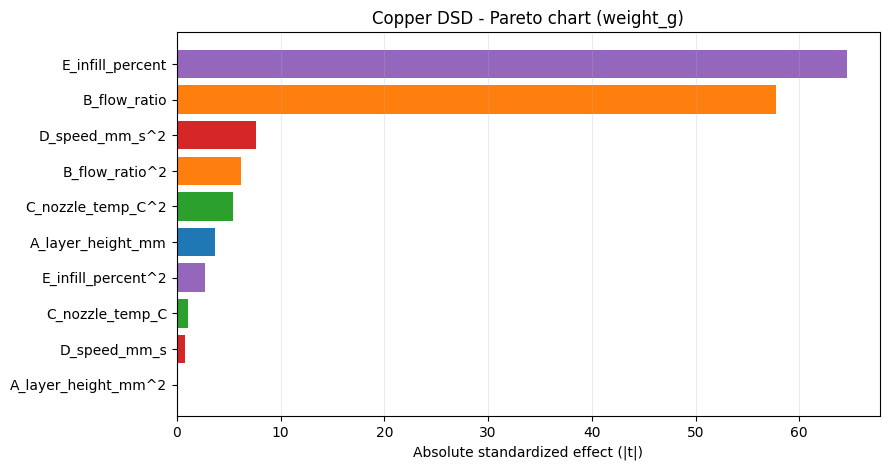

In [ ]:
if measured_count >= len(copper_model_terms) + 1:
    copper_response_model = fit_copper_response_model(
        copper_coded_response_table,
        response=COPPER_RESPONSE,
        terms=copper_model_terms,
    )
    display(copper_response_model["coefficient_df"].round(4))
    plot_copper_pareto(copper_response_model)
else:
    copper_response_model = None
    print("Not enough measured runs yet for the selected model terms.")

### 2. Normal And Half-Normal Plots Of Effects

The normal plot keeps the sign of the effect: positive means the response increases from low to high, and negative means it decreases. The half-normal plot focuses only on magnitude.

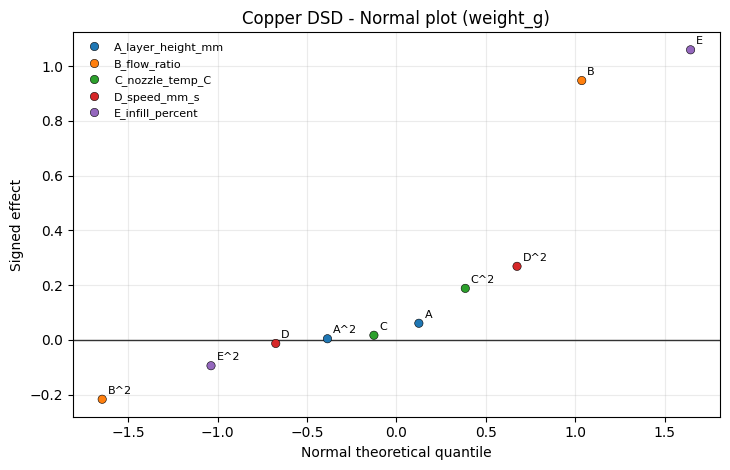

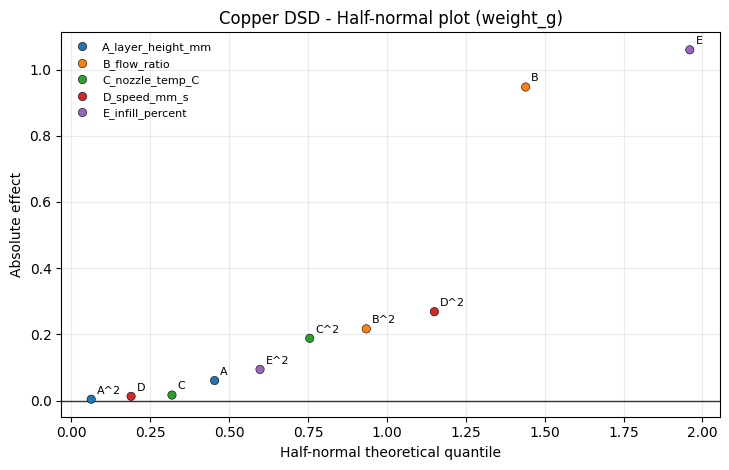

In [ ]:
if copper_response_model is not None:
    plot_copper_normal_effects(copper_response_model, half_normal=False)
    plot_copper_normal_effects(copper_response_model, half_normal=True)
else:
    print("Fit a model first to show normal and half-normal effect plots.")

### 3. Main Effects Plots

These plots show the mean response at low, center, and high levels for each factor. A steep line suggests a strong main effect. A curved line suggests possible quadratic behavior.

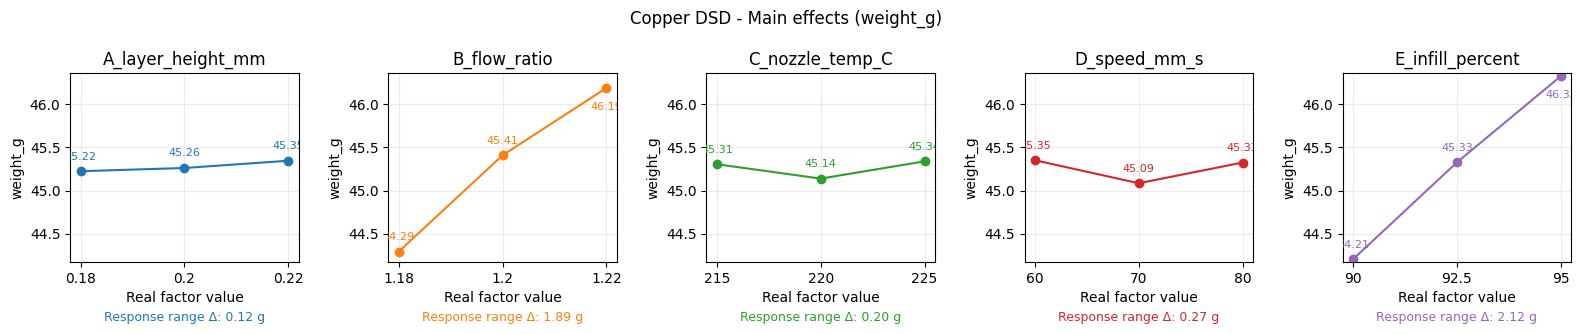

In [ ]:
plot_copper_main_effects(
    copper_coded_response_table,
    copper_factor_levels,
    response=COPPER_RESPONSE,
    factor_names=copper_factor_names,
)

### 4. Curvature Plots

The DSD uses three levels, so the full 13-run dataset can estimate individual quadratic terms such as flow ratio squared, temperature squared, speed squared, layer height squared, and infill squared.

,term,coefficient,standard_error,standardized_effect,absolute_standardized_effect,absolute_coefficient
0,Intercept,45.1645,0.0496,910.5565,910.5565,45.1645
1,A_layer_height_mm,0.0607,0.0164,3.6978,3.6978,0.0607
2,B_flow_ratio,0.9473,0.0164,57.7090,57.7090,0.9473
3,C_nozzle_temp_C,0.0169,0.0164,1.0295,1.0295,0.0169
4,D_speed_mm_s,-0.0130,0.0164,-0.7920,0.7920,0.0130
5,E_infill_percent,1.0596,0.0164,64.5502,64.5502,1.0596
6,A_layer_height_mm^2,0.0042,0.0351,0.1196,0.1196,0.0042
7,B_flow_ratio^2,-0.2168,0.0351,-6.1815,6.1815,0.2168
8,C_nozzle_temp_C^2,0.1882,0.0351,5.3658,5.3658,0.1882
9,D_speed_mm_s^2,0.2687,0.0351,7.6610,7.6610,0.2687


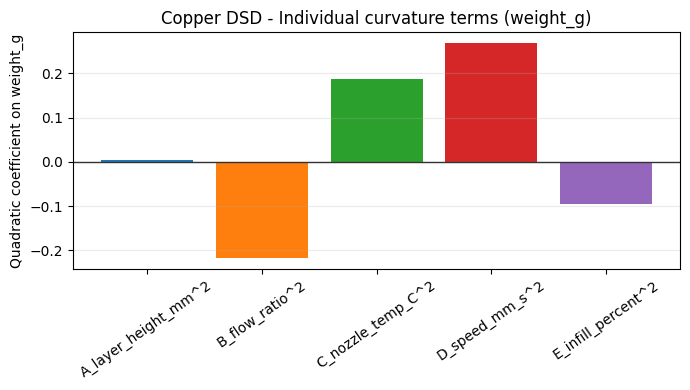

In [ ]:
if measured_count >= len(quadratic_terms) + 1:
    copper_quadratic_model = fit_copper_response_model(
        copper_coded_response_table,
        response=COPPER_RESPONSE,
        terms=quadratic_terms,
    )
    display(copper_quadratic_model["coefficient_df"].round(4))
    plot_copper_curvature(copper_quadratic_model)
else:
    copper_quadratic_model = None
    print("Curvature plot waits for enough measured runs to fit main effects plus five quadratic terms.")

### 5. Selected Interaction Plots

Only physically plausible interactions are prepared here. Crossing or strongly nonparallel lines suggest an interaction. Do not fit every possible interaction simultaneously with only 13 runs.

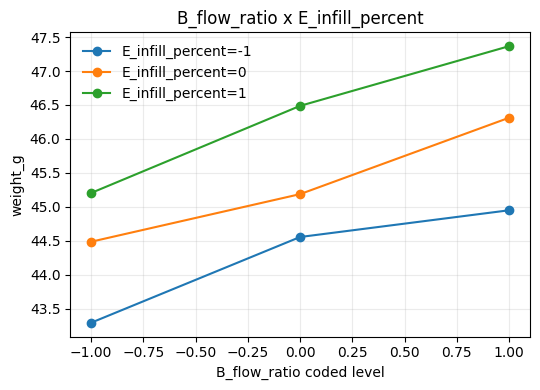

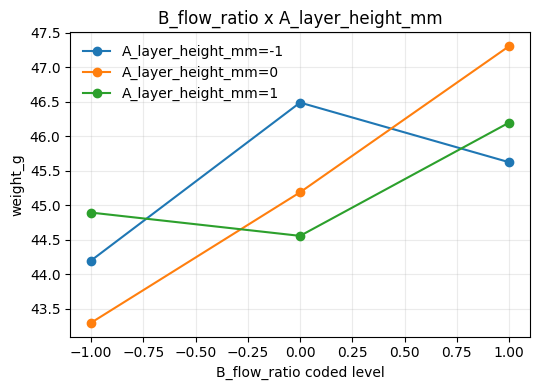

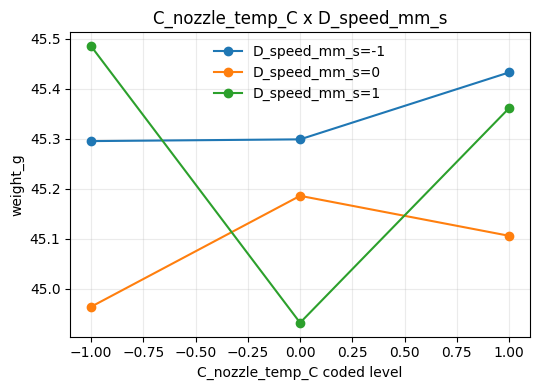

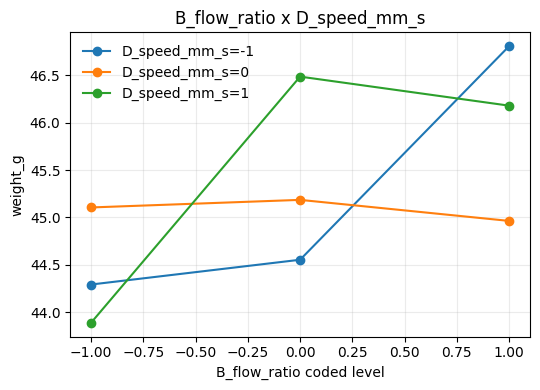

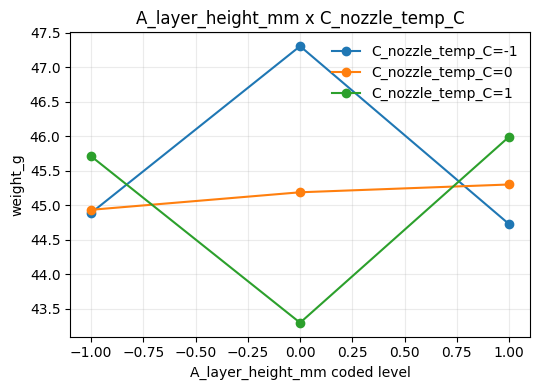

In [ ]:
plot_copper_interactions(
    copper_coded_response_table,
    response=COPPER_RESPONSE,
    interaction_pairs=COPPER_SELECTED_INTERACTIONS,
)

### 6. Actual Versus Predicted Plot

This compares measured response values with model predictions. Points close to the diagonal indicate good agreement. Large deviations can indicate outliers, missing terms, or experimental variation.

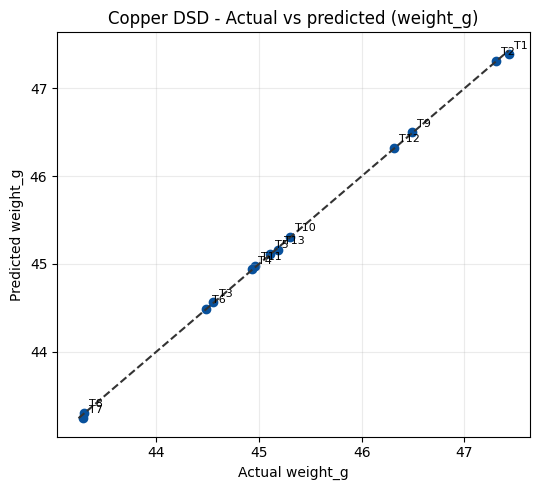

In [ ]:
if copper_response_model is not None:
    plot_copper_actual_vs_predicted(copper_response_model)
else:
    print("Fit a model first to show actual versus predicted values.")

### 7. Residual Plots

Residual diagnostics include residuals versus predicted values, a normal probability plot, residuals versus print order, and residuals versus each factor. Residuals versus print order are especially important because nozzle condition, filament condition, room conditions, and machine heating can drift during Filamet experiments.

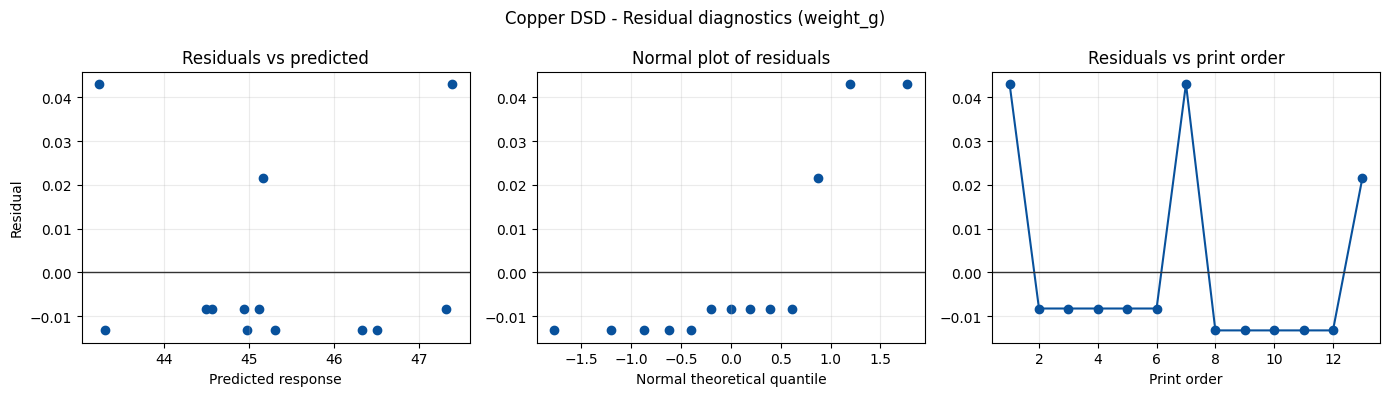

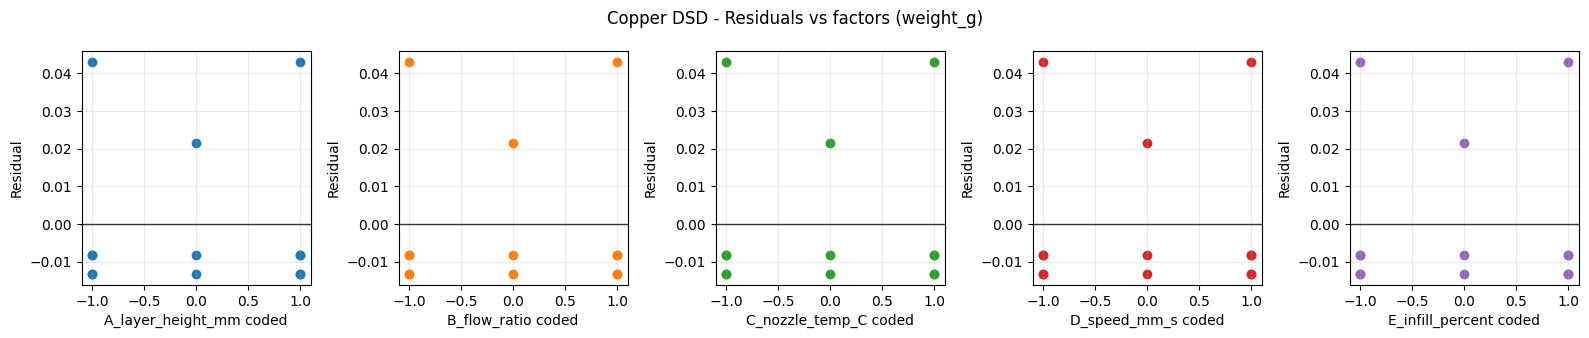

In [ ]:
if copper_response_model is not None:
    plot_copper_residuals(copper_response_model, copper_factor_names)
else:
    print("Fit a model first to show residual diagnostics.")

### 8. Contour Plots

Use contour plots only after choosing a reduced final model. The prepared examples are flow ratio against layer height, flow ratio against temperature, and temperature against speed.

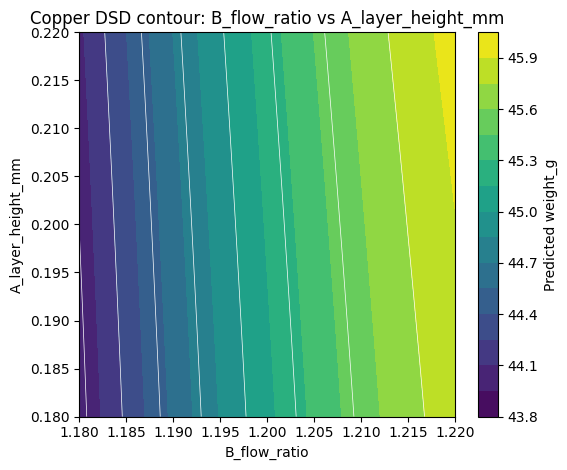

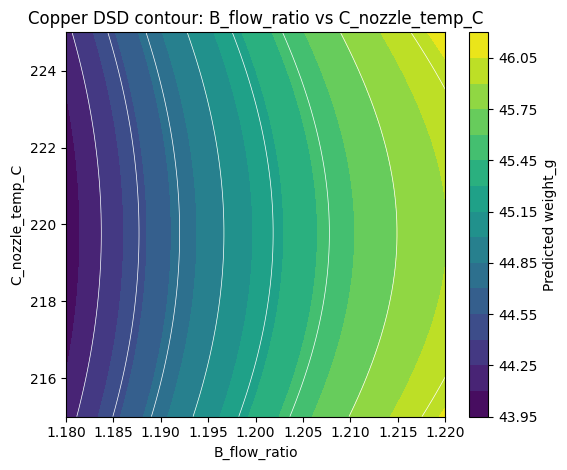

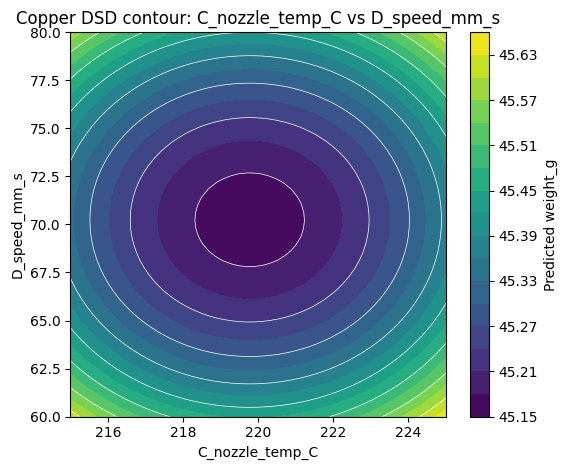

In [ ]:
final_contour_model = copper_quadratic_model or copper_response_model
if final_contour_model is not None:
    plot_copper_contours(
        final_contour_model,
        levels=copper_factor_levels,
        factor_pairs=COPPER_CONTOUR_PAIRS,
        fixed_level=0,
    )
else:
    print("Fit a reduced model first to show contour plots.")

### 9. Multiresponse Desirability

This combines available responses into one compromise score. Density is maximised. Porosity, leakage, and visible clumping are minimised. The desirability table updates automatically once those columns are filled in the measurement JSON.

In [ ]:
copper_desirability_table = build_copper_desirability_table(copper_measurement_table)
display(copper_desirability_table[[
    "Run",
    "density_g_cm3",
    "porosity_percent",
    "log_leakage_rate",
    "visible_clumping_score",
    "overall_desirability",
]])
plot_copper_desirability(copper_desirability_table)

,Run,density_g_cm3,porosity_percent,log_leakage_rate,visible_clumping_score,overall_desirability
0,T1,None,None,None,None,NaN
1,T2,None,None,None,None,NaN
2,T3,None,None,None,None,NaN
3,T4,None,None,None,None,NaN
4,T5,None,None,None,None,NaN
5,T6,None,None,None,None,NaN
6,T7,None,None,None,None,NaN
7,T8,None,None,None,None,NaN
8,T9,None,None,None,None,NaN
9,T10,None,None,None,None,NaN


No desirability plot yet: add density, porosity, leakage, or clumping responses.
